In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from google.colab import drive


In [3]:
drive.mount("/content/drive")

dossier = "/content/drive/MyDrive/metal_mining/"
meta = pd.read_csv(dossier + "chansons_en_13_classes.csv")
X_par_methode = np.load(dossier + "X_par_methode_13_classes.npz")

X_moyenne = X_par_methode["moyenne"]
y = meta["genre"].values
groups = meta["groupe"].values

print(X_moyenne.shape, len(meta))
print(meta.columns.tolist())

Mounted at /content/drive
(32486, 768) 32486
['groupe', 'album', 'type', 'année', 'titre', 'track_number', 'langue', 'paroles', 'genre']


In [4]:
from sklearn.manifold import TSNE

def tracer_tsne(X_m, y, titre, metric="euclidean", perplexities=[50]):
    fig, axes = plt.subplots(1, len(perplexities),
                             figsize=(6 * len(perplexities), 5), squeeze=False)
    axes = axes.ravel()
    for ax, p in zip(axes, perplexities):
        E = TSNE(n_components=2, perplexity=p, random_state=0,
                 max_iter=1000, metric=metric).fit_transform(X_m)
        couleurs = plt.get_cmap("tab20")
        genres_uniques = np.unique(y)
        for i, genre in enumerate(genres_uniques):
          masque = y == genre
          ax.scatter(E[masque, 0], E[masque, 1], label=genre, s=5, color=couleurs(i))
        ax.set_title(f"perplexity={p}")
    axes[0].legend(markerscale=3)
    axes[-1].legend(markerscale=3, bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.suptitle(titre)
    plt.show()

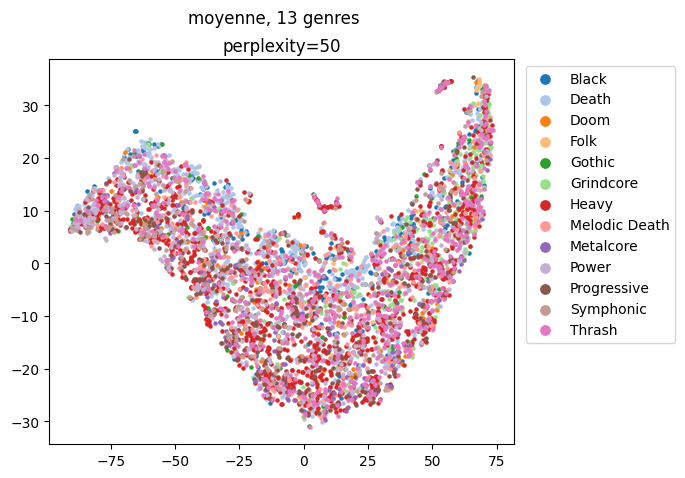

In [5]:
nb_chansons_tsne = 5000
rng = np.random.default_rng(0)
indices_tsne = rng.choice(len(meta), size=nb_chansons_tsne, replace=False)

tracer_tsne(X_moyenne[indices_tsne], y[indices_tsne], "moyenne, 13 genres")

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

cv = StratifiedGroupKFold(n_splits=5)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=42)),
])

Cs = {"clf__C": np.logspace(-4, 2, 7)}

grid = GridSearchCV(
    estimator=pipeline,
    cv=cv,
    param_grid=Cs,
    n_jobs=-1,
)

train_idx, test_idx = next(cv.split(X_moyenne, y, groups))
print(len(train_idx), len(test_idx))

grid.fit(X_moyenne[train_idx], y[train_idx], groups=groups[train_idx])

meilleur_C = grid.best_params_["clf__C"]
print(f"Score de validation (meilleur C) : {grid.best_score_:.3f}")
print(f"Meilleur C : {meilleur_C}")
print(f"Score de test : {grid.score(X_moyenne[test_idx], y[test_idx]):.3f}")

predictions_test = grid.predict(X_moyenne[test_idx])
print(classification_report(y[test_idx], predictions_test))

25986 6500
Score de validation (meilleur C) : 0.370
Meilleur C : 0.001
Score de test : 0.391
               precision    recall  f1-score   support

        Black       0.25      0.24      0.24       441
        Death       0.37      0.42      0.39       882
         Doom       0.02      0.00      0.01       206
         Folk       0.21      0.09      0.13        86
       Gothic       0.09      0.02      0.04       161
    Grindcore       0.44      0.37      0.40       294
        Heavy       0.52      0.77      0.62      1551
Melodic Death       0.27      0.22      0.24       569
    Metalcore       0.45      0.47      0.46       232
        Power       0.40      0.32      0.35       652
  Progressive       0.21      0.19      0.20       416
    Symphonic       0.17      0.09      0.11       294
       Thrash       0.33      0.29      0.31       716

     accuracy                           0.39      6500
    macro avg       0.29      0.27      0.27      6500
 weighted avg       0.35 

In [8]:
# Code généré par Claude pour adapter la régression logistique
# de la cellule précédente (sklearn, CPU) à un GPU (cuML).


In [ ]:
from cuml.linear_model import LogisticRegression as LogReg_gpu
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report

cv = StratifiedGroupKFold(n_splits=5)

encodeur = LabelEncoder().fit(y)
y_codes = encodeur.transform(y)

def ajuster_et_predire(X_a, y_a, X_b, C):
    scaler = StandardScaler().fit(X_a)
    modele = LogReg_gpu(C=C, max_iter=5000, output_type="numpy")
    modele.fit(scaler.transform(X_a).astype("float32"), y_a)
    return modele.predict(scaler.transform(X_b).astype("float32"))

def evaluer(nom_methode, train_idx, test_idx):
    X = X_par_methode[nom_methode]
    print(nom_methode, X.shape)
    X_train, y_train, g_train = X[train_idx], y_codes[train_idx], groups[train_idx]

    scores_validation = {}
    for C in np.logspace(-4, 2, 7):
        debut = time.time()
        scores = []
        for a, b in cv.split(X_train, y_train, g_train):
            pred = ajuster_et_predire(X_train[a], y_train[a], X_train[b], C)
            scores.append(accuracy_score(y_train[b], pred))
        scores_validation[C] = np.mean(scores)
        print(f"C={C:.4g}  validation={scores_validation[C]:.3f}  ({time.time() - debut:.0f} s)")

    meilleur_C = max(scores_validation, key=scores_validation.get)
    pred_test = ajuster_et_predire(X_train, y_train, X[test_idx], meilleur_C)

    exactitude = accuracy_score(y_codes[test_idx], pred_test)
    f1_macro = f1_score(y_codes[test_idx], pred_test, average="macro")
    print(f"Meilleur C : {meilleur_C}")
    print(f"Validation : {scores_validation[meilleur_C]:.3f}")
    print(f"Test : exactitude={exactitude:.3f}  F1 macro={f1_macro:.3f}")
    print(classification_report(y_codes[test_idx], pred_test,
                                target_names=encodeur.classes_))
    return exactitude, f1_macro

train_idx, test_idx = next(cv.split(X_par_methode["moyenne"], y, groups))
print(len(train_idx), len(test_idx))        # attendu : 25986 6500
print(set(groups[train_idx]) & set(groups[test_idx]))   # attendu : set()

resultats = {}
for nom_methode in ["moyenne", "moyenne_variance"]:
    resultats[nom_methode] = evaluer(nom_methode, train_idx, test_idx)

25986 6500
set()
moyenne (32486, 768)
[2026-10-28 22:28:44.265] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step
C=0.0001  validation=0.368  (9 s)
C=0.001  validation=0.370  (3 s)
[2026-10-28 22:28:48.560] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step
C=0.01  validation=0.359  (3 s)
C=0.1  validation=0.340  (4 s)
C=1  validation=0.323  (5 s)
C=10  validation=0.319  (8 s)
C=100  validation=0.318  (9 s)
Meilleur C : 0.001
Validation : 0.370
Test : exactitude=0.391  F1 macro=0.270
               precision    recall  f1-score   support

        Black       0.25      0.24      0.24       441
        Death       0.37      0.42      0.39       882
         Doom       0.02      0.00      0.01       206
         Folk       0.21      0.09      0.13        86
       Gothic       0.09      0.02      0.04       161
    Grindcore       0.44      0.37      0.40       294
        Heavy       0.52      0.77      0.62      1551
M

In [ ]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(train_idx), 1)), y_codes[train_idx])
pred_dummy = dummy.predict(np.zeros((len(test_idx), 1)))

exactitude_dummy = accuracy_score(y_codes[test_idx], pred_dummy)
f1_macro_dummy = f1_score(y_codes[test_idx], pred_dummy, average="macro", zero_division=0)

print("Classe prédite :", encodeur.classes_[pred_dummy[0]])
resultats["dummy"] = (exactitude_dummy, f1_macro_dummy)

for nom, (exactitude, f1_macro) in resultats.items():
    print(f"{nom:20s} exactitude={exactitude:.3f}  F1 macro={f1_macro:.3f}")

Classe prédite : Heavy
moyenne              exactitude=0.391  F1 macro=0.270
moyenne_variance     exactitude=0.393  F1 macro=0.260
dummy                exactitude=0.239  F1 macro=0.030
